# SAM for SEM microstructures: robustness and stability

This teaching notebook adapts the supplied **Noise Sensitivity Analysis with Trajectory Analysis** workflow to one focused question:

> **How much SEM image degradation can Meta's original Segment Anything Model (SAM) tolerate before its internal representation meaningfully changes?**

We study the pooled 256-dimensional output of SAM's ViT-B image encoder. We do **not** compare against a VAE or two-point correlations. Most of the notebook studies representation robustness; a final, clearly separated section studies the local **prediction stability** of SAM's mask decoder under fixed prompts.


## Learning goals and experimental logic

By the end, you should be able to distinguish five complementary views of robustness and stability:

1. **Image-level stability:** Does one degraded image remain close to its own clean embedding?
2. **Neighbourhood stability:** Is its nearest clean reference still the correct image?
3. **Population stability:** Does the geometry of the complete image collection deform?
4. **Visual trajectory:** What does movement look like in a two-dimensional PCA projection?
5. **Local prediction stability:** Do fixed-prompt masks change under small, filter-normalized mask-decoder perturbations?

The first three are computed in the **full 256-D SAM representation space**. PCA is fitted only on clean embeddings and is used strictly as a visualization. A visually dramatic PCA path is not, by itself, proof of a large full-space change.

### Controlled comparison
We create Gaussian, Poisson, blur, and salt-and-pepper degradations. Their physical parameters are not directly comparable, so a deterministic binary search matches each image to requested **SSIM** levels. The measured SSIM is retained because exact matching is not always possible. Blur receives a dataset-specific range: some microstructures reach a high SSIM floor even under extreme blur.


In [1]:
from pathlib import Path
import hashlib
import json
import os
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from PIL import Image
from scipy.spatial import procrustes
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler, normalize
from skimage.filters import gaussian
from skimage.metrics import structural_similarity
from tqdm.auto import tqdm

from segment_anything import SamPredictor, sam_model_registry

sns.set_theme(style="whitegrid", context="notebook")
SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

PROJECT_ROOT = Path.cwd()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "demonstrations").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "demonstrations").is_dir(), "Run the notebook from inside the repository."
IMAGE_DIR = PROJECT_ROOT / "demonstrations/data/trajectory images"
SAM_CHECKPOINT = PROJECT_ROOT / "weights/segment-anything/sam_vit_b_01ec64.pth"
ARTIFACT_DIR = PROJECT_ROOT / "artifacts/sam_sem_robustness"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Set SAM_ROBUSTNESS_SMOKE=1 before execution for a short validation run.
SMOKE_TEST = os.getenv("SAM_ROBUSTNESS_SMOKE", "0") == "1"
MAX_IMAGES = 3 if SMOKE_TEST else 10
N_LEVELS = 1 if SMOKE_TEST else 4
FORCE_RECOMPUTE = False

assert IMAGE_DIR.is_dir(), f"Image directory not found: {IMAGE_DIR}"
assert SAM_CHECKPOINT.is_file(), f"Checkpoint not found: {SAM_CHECKPOINT}"
print(f"Mode: {'SMOKE TEST' if SMOKE_TEST else 'FULL TEACHING RUN'}")
print(f"Images: up to {MAX_IMAGES}; degradation levels per noise type: {N_LEVELS}")


Mode: FULL TEACHING RUN
Images: up to 10; degradation levels per noise type: 4


## 1. Load and inspect the clean SEM images

All images are converted to grayscale, resized to 512×512 if needed, converted to `float32`, and normalized to [0, 1]. Min–max normalization is performed once, before degradation; degraded images are only clipped, not renormalized. This prevents normalization from partly undoing the intended corruption.


Loaded 10 images with shape (512, 512) from demonstrations/data/trajectory images


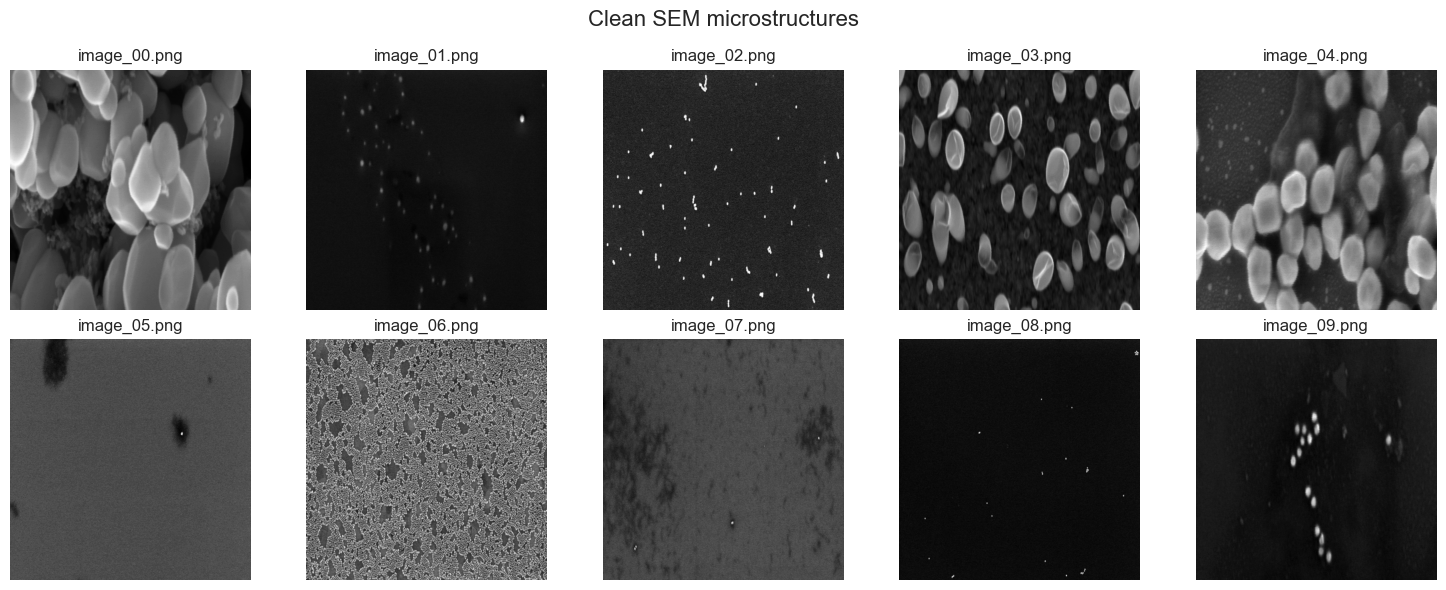

In [2]:
VALID_SUFFIXES = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}
image_paths = sorted(p for p in IMAGE_DIR.iterdir() if p.suffix.lower() in VALID_SUFFIXES)[:MAX_IMAGES]
assert len(image_paths) >= 3, "At least three images are needed for trajectories and neighbour analysis."

def load_sem_image(path, size=512):
    image = Image.open(path).convert("L")
    if image.size != (size, size):
        image = image.resize((size, size), Image.Resampling.BILINEAR)
    array = np.asarray(image, dtype=np.float32)
    lo, hi = float(array.min()), float(array.max())
    if hi > lo:
        array = (array - lo) / (hi - lo)
    else:
        array = np.zeros_like(array)
    return array

clean_images = np.stack([load_sem_image(p) for p in image_paths])
filenames = np.array([p.name for p in image_paths])
print(f"Loaded {len(clean_images)} images with shape {clean_images.shape[1:]} from {IMAGE_DIR.relative_to(PROJECT_ROOT)}")

fig, axes = plt.subplots(2, int(np.ceil(len(clean_images) / 2)), figsize=(15, 6))
for ax, image, name in zip(np.ravel(axes), clean_images, filenames):
    ax.imshow(image, cmap="gray", vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis("off")
for ax in np.ravel(axes)[len(clean_images):]:
    ax.axis("off")
fig.suptitle("Clean SEM microstructures", fontsize=16)
plt.tight_layout()


## 2. Generate SSIM-matched degradation trajectories

The functions below retain the source notebook's four noise models and SSIM matching, with two reproducibility improvements:

- every search uses a fixed random seed, so evaluating the same parameter gives the same image;
- the best observed match is returned even when stochastic/discrete noise prevents exact convergence.

**SSIM is a control variable, not a verdict on scientific usefulness.** Two corruptions with the same SSIM can alter microstructural evidence very differently.


In [3]:
NOISE_TYPES = ("gaussian", "poisson", "blur", "salt_pepper")
DISPLAY_NAME = {"gaussian": "Gaussian", "poisson": "Poisson", "blur": "Blur", "salt_pepper": "Salt & pepper"}

def image_ssim(reference, candidate):
    return float(structural_similarity(reference, candidate, data_range=1.0))

def degrade(image, noise_type, strength, seed):
    local_rng = np.random.default_rng(seed)
    if noise_type == "gaussian":
        out = image + local_rng.normal(0.0, strength, image.shape)
    elif noise_type == "poisson":
        peak = max(float(strength), 1e-4)
        out = local_rng.poisson(np.clip(image, 0, 1) * peak) / peak
    elif noise_type == "blur":
        out = gaussian(image, sigma=strength, preserve_range=True)
    elif noise_type == "salt_pepper":
        amount = float(np.clip(strength, 0, 1))
        draws = local_rng.random(image.shape)
        out = image.copy()
        out[draws < amount / 2] = 0.0
        out[(draws >= amount / 2) & (draws < amount)] = 1.0
    else:
        raise ValueError(f"Unknown noise type: {noise_type}")
    return np.clip(out, 0, 1).astype(np.float32)

def match_target_ssim(image, noise_type, target, seed, tolerance=0.012, max_iter=28):
    # Poisson strength is peak electron count: larger means cleaner. Search in log space.
    if noise_type == "poisson":
        low, high = -2.0, 5.0
        to_strength = lambda x: 10.0 ** x
        cleaner_when_larger = True
    else:
        bounds = {"gaussian": (0.0, 1.0), "blur": (0.0, 50.0), "salt_pepper": (0.0, 1.0)}
        low, high = bounds[noise_type]
        to_strength = lambda x: x
        cleaner_when_larger = False

    best = None
    for _ in range(max_iter):
        middle = (low + high) / 2
        strength = to_strength(middle)
        candidate = degrade(image, noise_type, strength, seed)
        measured = image_ssim(image, candidate)
        error = abs(measured - target)
        if best is None or error < best[0]:
            best = (error, candidate, measured, strength)
        if error <= tolerance:
            break
        if cleaner_when_larger:
            if measured < target:
                low = middle
            else:
                high = middle
        else:
            if measured < target:
                high = middle
            else:
                low = middle
    _, candidate, measured, strength = best
    return candidate, measured, strength

# A common wide range works for additive/shot/impulse noise. Blur needs a data-driven floor.
wide_targets = np.array([0.85] if SMOKE_TEST else [0.95, 0.80, 0.65, 0.50])
blur_floors = np.array([image_ssim(img, degrade(img, "blur", 50.0, SEED)) for img in clean_images])
safe_blur_floor = float(blur_floors.max())
blur_low = min(0.97, np.ceil((safe_blur_floor + 0.01) * 100) / 100)
blur_targets = np.array([0.95] if SMOKE_TEST else np.linspace(0.98, blur_low, N_LEVELS))
targets_by_noise = {n: (blur_targets if n == "blur" else wide_targets) for n in NOISE_TYPES}
print(f"Observed per-image extreme-blur SSIM floors: {np.round(blur_floors, 3)}")
print(f"Safe blur targets: {np.round(blur_targets, 3)}")


Observed per-image extreme-blur SSIM floors: [0.611 0.903 0.47  0.482 0.55  0.633 0.057 0.626 0.847 0.848]
Safe blur targets: [0.98 0.96 0.94 0.92]


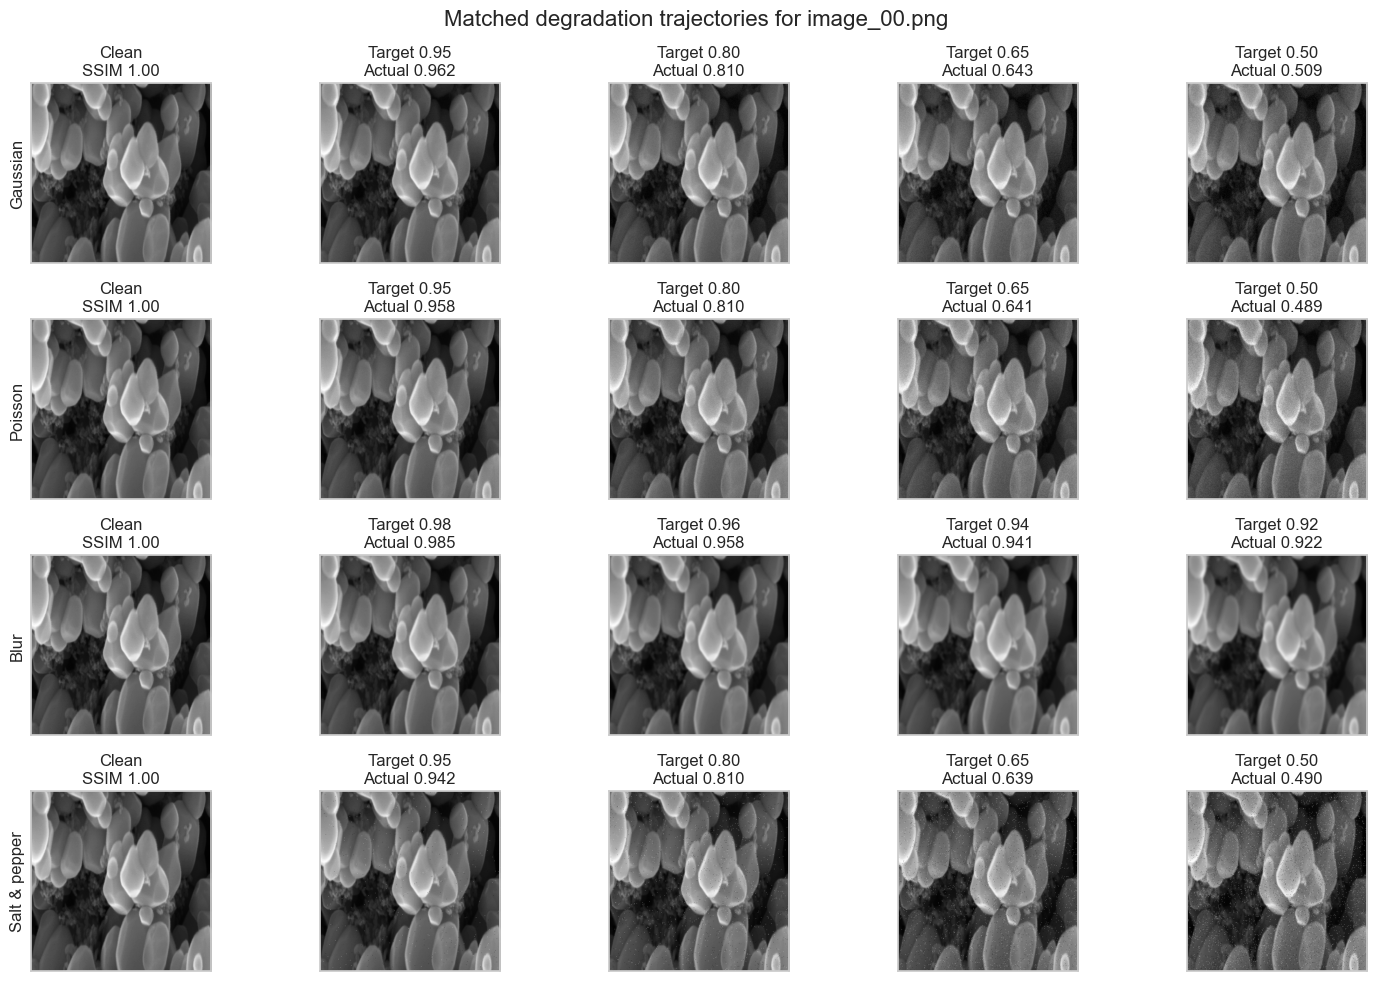

In [4]:
preview_index = 0
fig, axes = plt.subplots(len(NOISE_TYPES), N_LEVELS + 1, figsize=(3.0 * (N_LEVELS + 1), 10))
for row, noise_type in enumerate(NOISE_TYPES):
    axes[row, 0].imshow(clean_images[preview_index], cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title("Clean\nSSIM 1.00")
    axes[row, 0].set_ylabel(DISPLAY_NAME[noise_type])
    for col, target in enumerate(targets_by_noise[noise_type], start=1):
        degraded, actual, strength = match_target_ssim(clean_images[preview_index], noise_type, target, SEED + row * 100 + col)
        axes[row, col].imshow(degraded, cmap="gray", vmin=0, vmax=1)
        axes[row, col].set_title(f"Target {target:.2f}\nActual {actual:.3f}")
    for ax in axes[row]:
        ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"Matched degradation trajectories for {filenames[preview_index]}", fontsize=16)
plt.tight_layout()


## 3. Extract pooled SAM image-encoder embeddings

SAM normally produces a 256×64×64 feature map for a square image. Following the source notebook, adaptive global-average pooling turns this map into one 256-D vector per image. This is convenient for trajectory analysis, but it discards spatial location. Conclusions therefore concern the **pooled SAM representation**, not every spatial feature and not the final segmentation masks.

The first full run computes clean and degraded embeddings and stores a compressed cache under `artifacts/sam_sem_robustness/`. Later runs reuse it when the configuration matches.


In [5]:
device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print("SAM device:", device)
sam = sam_model_registry["vit_b"](checkpoint=str(SAM_CHECKPOINT)).to(device).eval()
predictor = SamPredictor(sam)
pool = nn.AdaptiveAvgPool2d((1, 1))

def to_sam_rgb(image):
    gray = np.clip(np.rint(image * 255), 0, 255).astype(np.uint8)
    return np.repeat(gray[..., None], 3, axis=2)

@torch.inference_mode()
def extract_sam_embedding(image):
    predictor.set_image(to_sam_rgb(image))
    feature_map = predictor.get_image_embedding()
    vector = pool(feature_map).flatten().detach().cpu().numpy().astype(np.float32)
    if not np.isfinite(vector).all():
        raise RuntimeError("SAM produced a non-finite embedding.")
    return vector

config = {
    "version": 2,
    "model": "sam_vit_b_01ec64",
    "files": filenames.tolist(),
    "targets": {k: np.asarray(v).round(6).tolist() for k, v in targets_by_noise.items()},
    "seed": SEED,
}
config_json = json.dumps(config, sort_keys=True)
cache_tag = hashlib.sha256(config_json.encode()).hexdigest()[:12]
CACHE_PATH = ARTIFACT_DIR / f"sam_vit_b_robustness_{cache_tag}.npz"
print("Cache:", CACHE_PATH.relative_to(PROJECT_ROOT))


SAM device: mps


Cache: artifacts/sam_sem_robustness/sam_vit_b_robustness_9d64c181717d.npz


In [6]:
def compute_study():
    started = time.perf_counter()
    clean_embeddings = np.stack([extract_sam_embedding(img) for img in tqdm(clean_images, desc="Clean SAM embeddings")])
    records, degraded_images, degraded_embeddings = [], [], []
    for noise_index, noise_type in enumerate(NOISE_TYPES):
        for level_index, target in enumerate(targets_by_noise[noise_type]):
            for image_index, image in enumerate(tqdm(clean_images, desc=f"{DISPLAY_NAME[noise_type]} target {target:.2f}", leave=False)):
                seed = SEED + noise_index * 100_000 + level_index * 1_000 + image_index
                degraded, actual, strength = match_target_ssim(image, noise_type, float(target), seed)
                degraded_images.append(degraded)
                degraded_embeddings.append(extract_sam_embedding(degraded))
                records.append((image_index, noise_type, float(target), actual, strength))
    print(f"Computed study in {(time.perf_counter() - started) / 60:.1f} minutes.")
    return clean_embeddings, np.stack(degraded_images), np.stack(degraded_embeddings), records

if CACHE_PATH.exists() and not FORCE_RECOMPUTE:
    cached = np.load(CACHE_PATH, allow_pickle=False)
    assert str(cached["config_json"]) == config_json
    clean_embeddings = cached["clean_embeddings"]
    degraded_images = cached["degraded_images"]
    degraded_embeddings = cached["degraded_embeddings"]
    metadata_matrix = cached["metadata"]
    records = [(int(r[0]), str(r[1]), float(r[2]), float(r[3]), float(r[4])) for r in metadata_matrix]
    print("Loaded cached embeddings.")
else:
    clean_embeddings, degraded_images, degraded_embeddings, records = compute_study()
    metadata_matrix = np.asarray(records, dtype=str)
    np.savez_compressed(CACHE_PATH, config_json=config_json, clean_embeddings=clean_embeddings, degraded_images=degraded_images, degraded_embeddings=degraded_embeddings, metadata=metadata_matrix)
    print("Saved cache.")

results = pd.DataFrame(records, columns=["image_index", "noise_type", "target_ssim", "actual_ssim", "strength"])
results["filename"] = filenames[results.image_index.to_numpy()]
print(f"Clean embeddings: {clean_embeddings.shape}; degraded embeddings: {degraded_embeddings.shape}")
display(results.groupby(["noise_type", "target_ssim"]).actual_ssim.agg(["mean", "min", "max"]).round(3))


Loaded cached embeddings.
Clean embeddings: (10, 256); degraded embeddings: (160, 256)


mean    min    max
noise_type  target_ssim                     
blur        0.92         0.921  0.914  0.930
            0.94         0.939  0.929  0.949
            0.96         0.963  0.952  0.970
            0.98         0.980  0.970  0.985
gaussian    0.50         0.503  0.492  0.510
            0.65         0.647  0.639  0.660
            0.80         0.802  0.790  0.812
            0.95         0.952  0.946  0.962
poisson     0.50         0.496  0.488  0.511
            0.65         0.645  0.638  0.655
            0.80         0.801  0.788  0.812
            0.95         0.952  0.939  0.961
salt_pepper 0.50         0.502  0.488  0.512
            0.65         0.648  0.639  0.657
            0.80         0.798  0.789  0.804
            0.95         0.949  0.939  0.954

## 4. Freeze the clean reference space

This is the central anti-leakage rule:

- L2 normalization is applied consistently to clean and degraded vectors.
- `StandardScaler.fit(...)` sees **only clean embeddings**.
- `PCA.fit(...)` sees **only scaled clean embeddings**.
- Degraded embeddings are transformed by those frozen clean-reference operations.

Cosine similarity, Euclidean distance, nearest-neighbour identity, and Procrustes disparity below use all 256 dimensions. PCA coordinates are kept in separate columns for visualization only.


In [7]:
clean_unit = normalize(clean_embeddings, axis=1)
degraded_unit = normalize(degraded_embeddings, axis=1)
reference_rows = clean_embeddings[results.image_index.to_numpy()]
reference_unit_rows = clean_unit[results.image_index.to_numpy()]

# Full-space, image-to-own-clean-reference metrics.
results["cosine_similarity"] = np.sum(degraded_unit * reference_unit_rows, axis=1)
results["euclidean_distance"] = np.linalg.norm(degraded_embeddings - reference_rows, axis=1)
results["relative_euclidean"] = results.euclidean_distance / np.maximum(np.linalg.norm(reference_rows, axis=1), 1e-12)
results["unit_euclidean"] = np.linalg.norm(degraded_unit - reference_unit_rows, axis=1)

# Retrieval-style neighbourhood identity in the full representation space.
similarity_to_all_clean = degraded_unit @ clean_unit.T
results["nearest_clean_index"] = similarity_to_all_clean.argmax(axis=1)
results["nearest_clean_filename"] = filenames[results.nearest_clean_index.to_numpy()]
results["identity_retained"] = results.nearest_clean_index == results.image_index

# Frozen clean-only scaler and PCA.
scaler = StandardScaler().fit(clean_unit)
clean_scaled = scaler.transform(clean_unit)
degraded_scaled = scaler.transform(degraded_unit)
pca = PCA(n_components=2, random_state=SEED).fit(clean_scaled)
clean_pca = pca.transform(clean_scaled)
degraded_pca = pca.transform(degraded_scaled)
results[["pc1", "pc2"]] = degraded_pca
print("Variance visible in PC1+PC2:", f"{pca.explained_variance_ratio_.sum():.1%}")
display(results.head())


Variance visible in PC1+PC2: 77.6%


,image_index,noise_type,target_ssim,actual_ssim,strength,filename,cosine_similarity,euclidean_distance,relative_euclidean,unit_euclidean,nearest_clean_index,nearest_clean_filename,identity_retained,pc1,pc2
0,0,gaussian,0.95,0.961633,0.007812,image_00.png,0.998680,0.098319,0.052179,0.051389,0,image_00.png,True,-20.181454,-9.343765
1,1,gaussian,0.95,0.945709,0.007812,image_01.png,0.999502,0.071542,0.031548,0.031544,1,image_01.png,True,6.622747,0.896106
2,2,gaussian,0.95,0.954477,0.011719,image_02.png,0.999984,0.013191,0.005725,0.005661,2,image_02.png,True,12.317678,1.057540
3,3,gaussian,0.95,0.951263,0.009766,image_03.png,0.995926,0.171668,0.090357,0.090269,3,image_03.png,True,-13.513008,5.514344
4,4,gaussian,0.95,0.950783,0.009766,image_04.png,0.999695,0.047370,0.024714,0.024710,4,image_04.png,True,-15.810762,-7.242044


## 5. Clean-reference PCA trajectories — visualization, not the final metric

Each line begins at a black clean point and moves as SSIM decreases. PCA can make directions and image-specific paths visible, but it shows only the variance percentage printed above. Use the full-space plots in the following sections for quantitative claims.


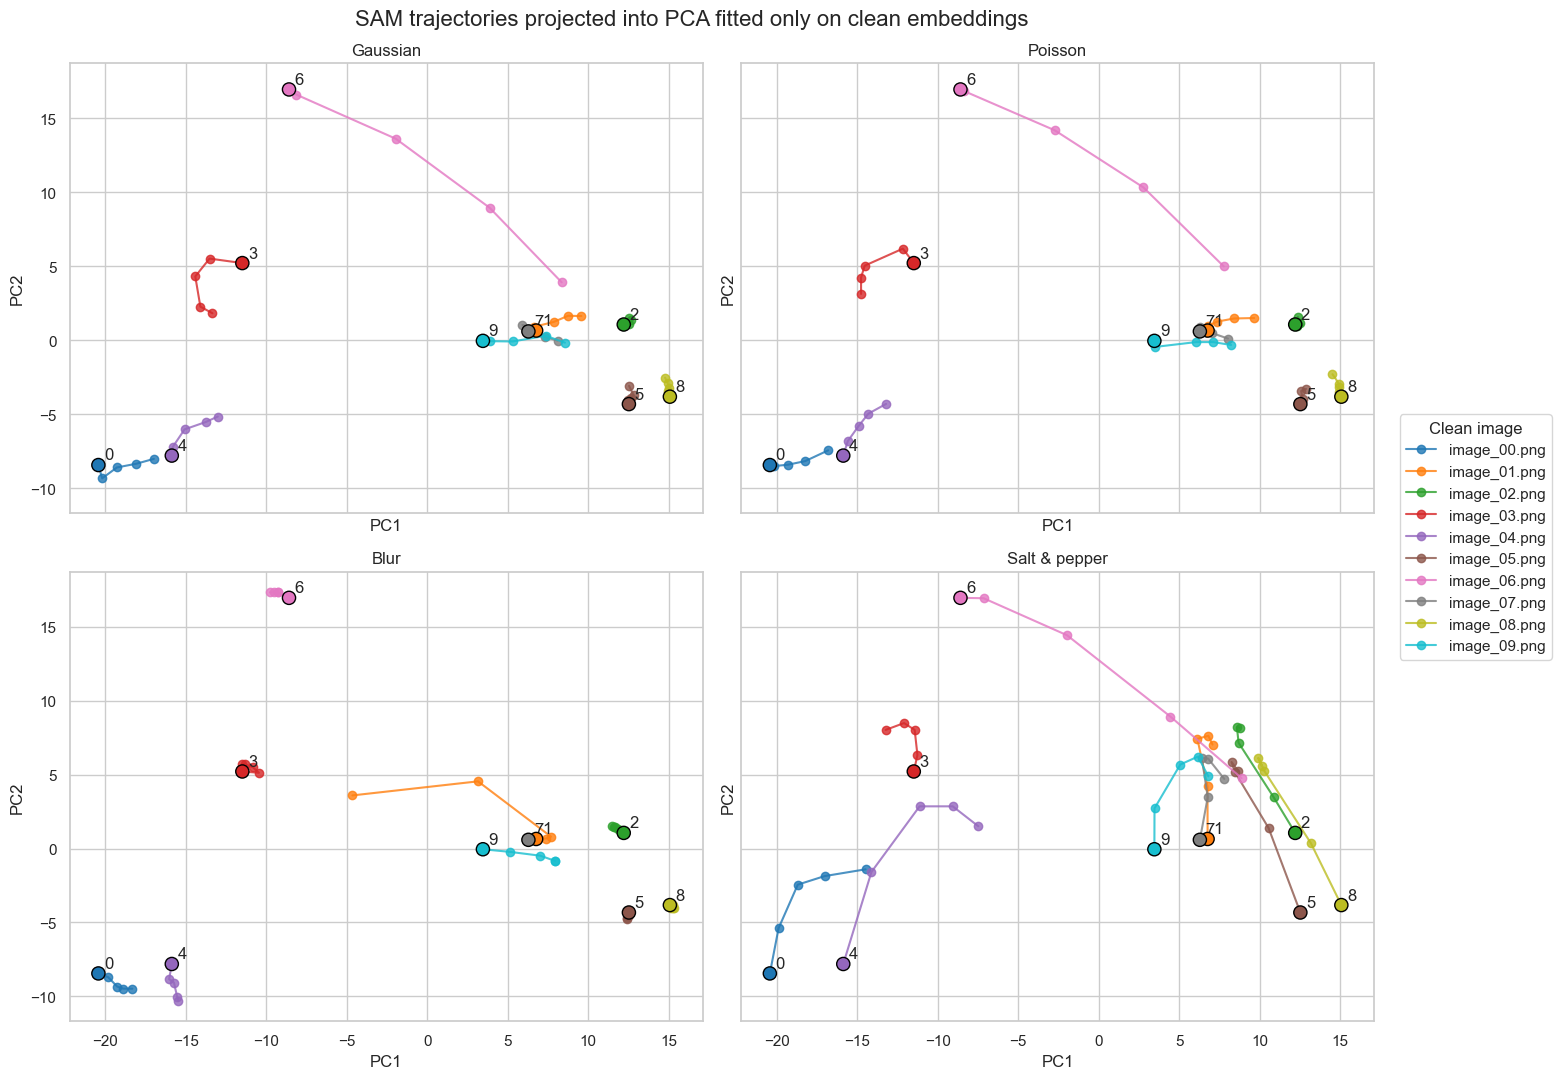

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11), sharex=True, sharey=True)
colors = plt.cm.tab10(np.linspace(0, 1, len(clean_images)))
for ax, noise_type in zip(axes.ravel(), NOISE_TYPES):
    ax.scatter(clean_pca[:, 0], clean_pca[:, 1], c=colors, s=90, edgecolor="black", zorder=4)
    for image_index in range(len(clean_images)):
        rows = results[(results.noise_type == noise_type) & (results.image_index == image_index)].sort_values("actual_ssim", ascending=False)
        x = np.r_[clean_pca[image_index, 0], rows.pc1]
        y = np.r_[clean_pca[image_index, 1], rows.pc2]
        ax.plot(x, y, marker="o", color=colors[image_index], alpha=0.8, label=filenames[image_index])
        ax.annotate(str(image_index), clean_pca[image_index], xytext=(4, 4), textcoords="offset points")
    ax.set_title(DISPLAY_NAME[noise_type])
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
fig.suptitle("SAM trajectories projected into PCA fitted only on clean embeddings", fontsize=16)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5), title="Clean image")
plt.tight_layout()


## 6. Full-space individual robustness

Cosine similarity asks whether the embedding direction is preserved. Euclidean distance asks how far the vector moves; the plotted relative distance divides by the clean vector norm so images with different baseline magnitudes are comparable. Points and pale lines show individual images, while the dark line shows the mean. Large spread is evidence that an aggregate average hides image-specific failures.


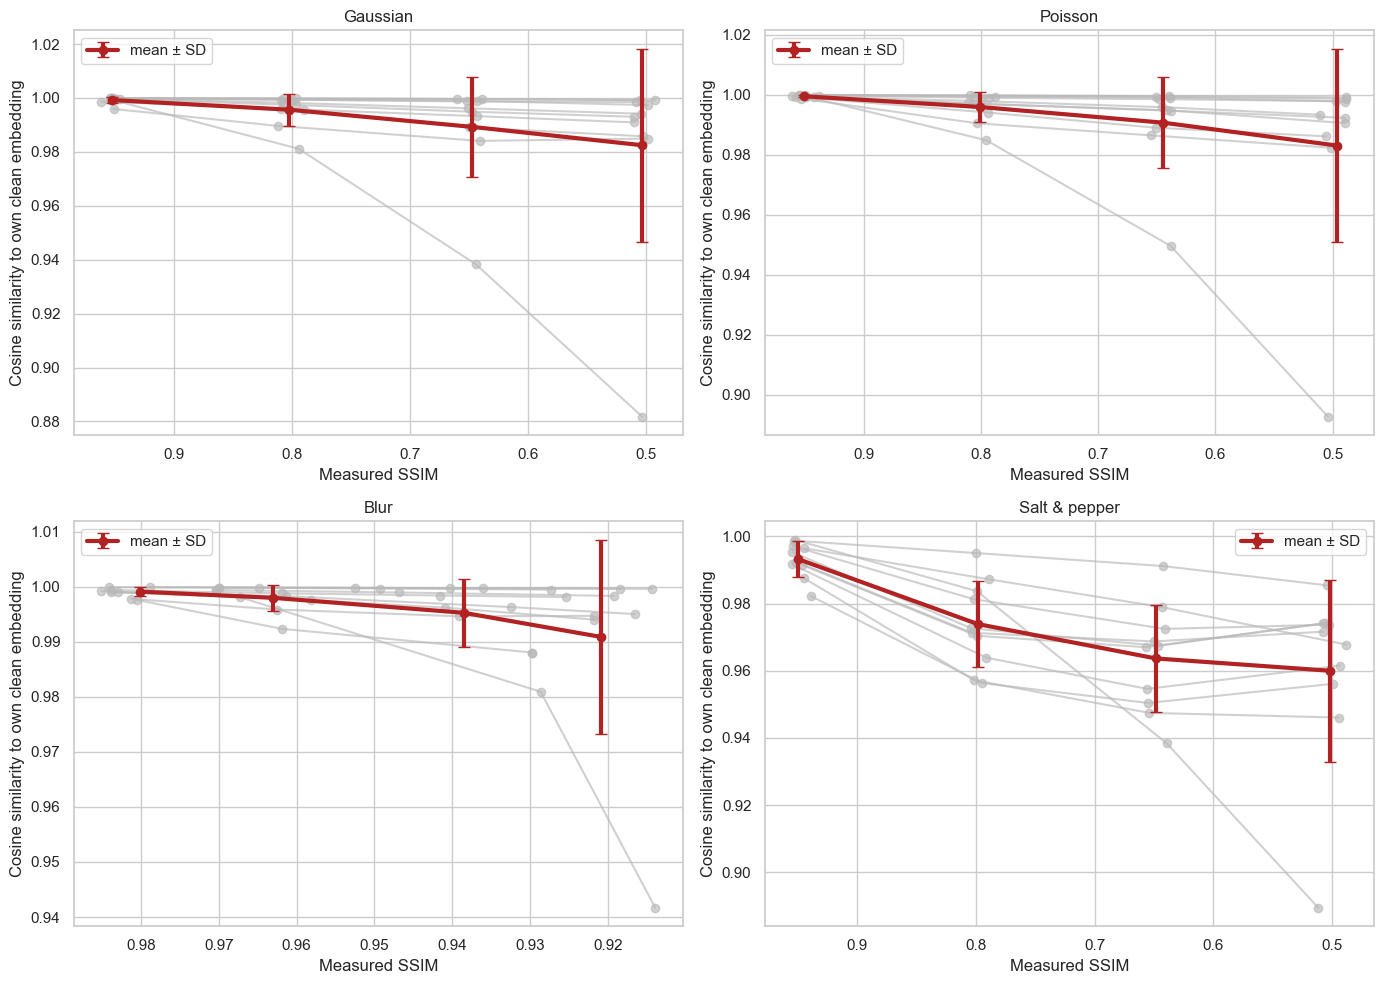

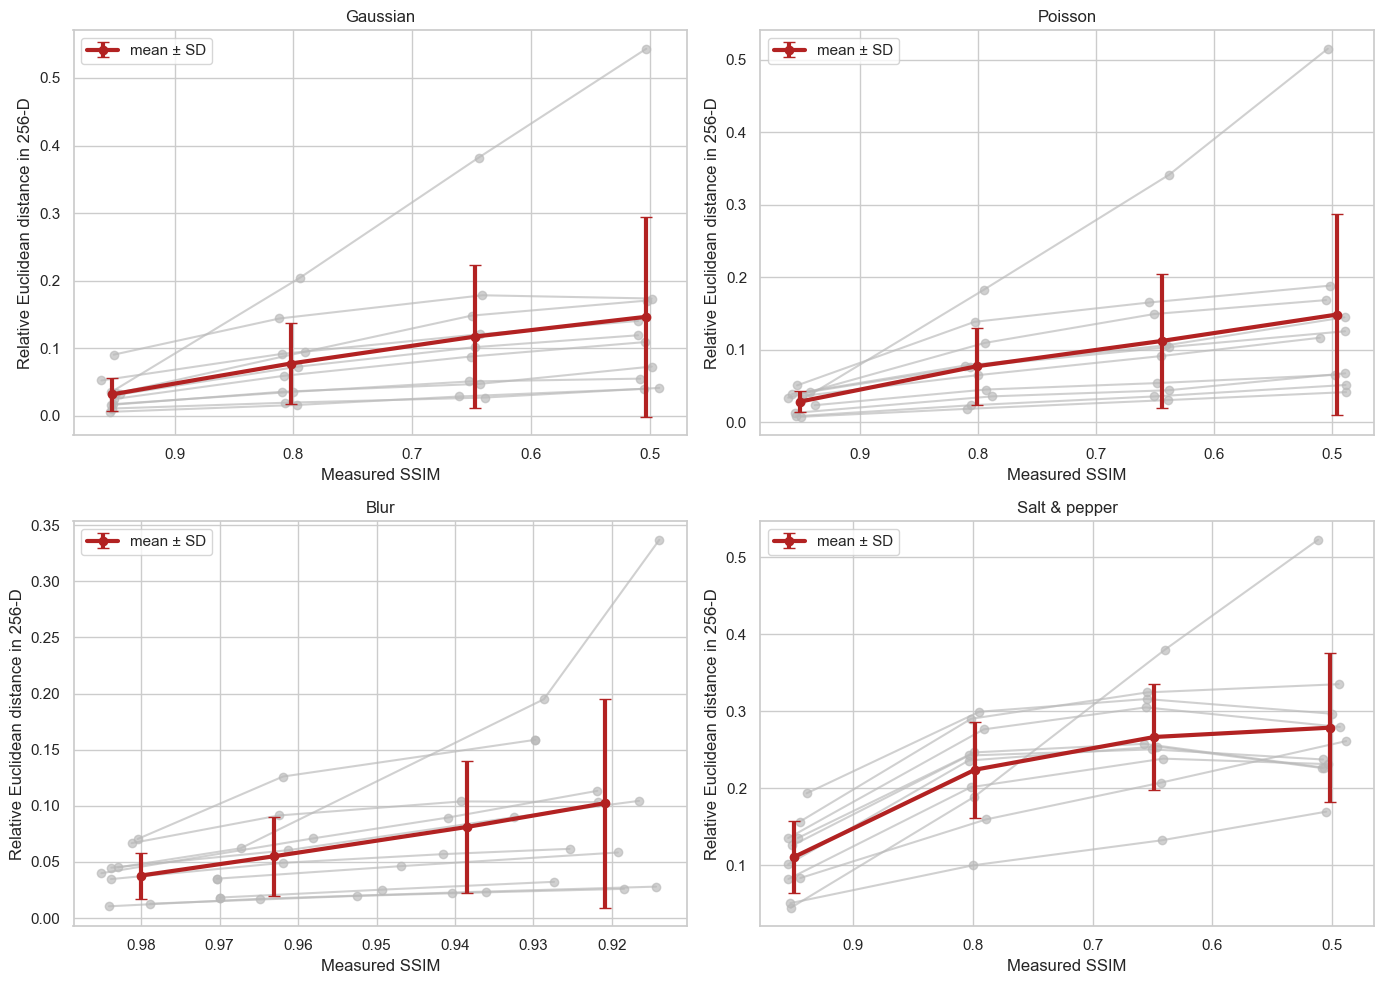

In [9]:
def plot_full_space_metric(metric, ylabel):
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    for ax, noise_type in zip(axes.ravel(), NOISE_TYPES):
        subset = results[results.noise_type == noise_type]
        for _, image_rows in subset.groupby("image_index"):
            image_rows = image_rows.sort_values("actual_ssim")
            ax.plot(image_rows.actual_ssim, image_rows[metric], color="0.72", marker="o", alpha=0.65)
        summary = subset.groupby("target_ssim").agg(actual_ssim=("actual_ssim", "mean"), mean=(metric, "mean"), std=(metric, "std")).sort_values("actual_ssim")
        ax.errorbar(summary.actual_ssim, summary["mean"], yerr=summary["std"].fillna(0), color="#B22222", marker="o", linewidth=3, capsize=4, label="mean ± SD")
        ax.set_title(DISPLAY_NAME[noise_type]); ax.set_xlabel("Measured SSIM"); ax.set_ylabel(ylabel)
        ax.invert_xaxis(); ax.legend()
    plt.tight_layout()

plot_full_space_metric("cosine_similarity", "Cosine similarity to own clean embedding")
plot_full_space_metric("relative_euclidean", "Relative Euclidean distance in 256-D")


## 7. Inspect the largest individual failures

A mean curve can look stable while one microstructure fails badly. For each corruption type, the next cell finds the lowest cosine-similarity case and displays its clean and degraded images. Ask whether the visually important morphology changed in the same way for every corruption.


,filename,actual_ssim,cosine_similarity,euclidean_distance,relative_euclidean,nearest_clean_filename
noise_type,,,,,,
gaussian,image_06.png,0.5029,0.8817,1.0607,0.5433,image_07.png
poisson,image_06.png,0.5038,0.8927,1.0056,0.5151,image_07.png
blur,image_01.png,0.9139,0.9417,0.7640,0.3369,image_03.png
salt_pepper,image_06.png,0.5116,0.8894,1.0211,0.5230,image_07.png


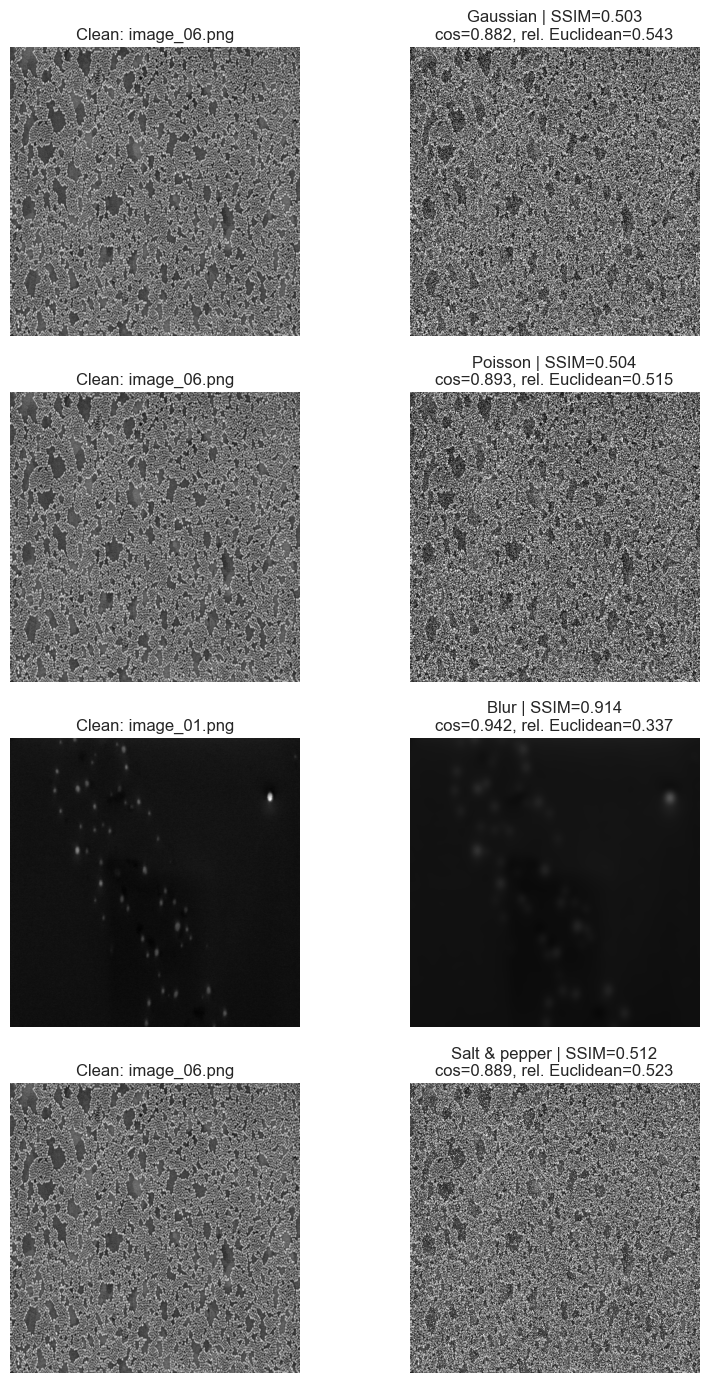

In [10]:
worst_indices = results.groupby("noise_type").cosine_similarity.idxmin()
worst = results.loc[worst_indices].set_index("noise_type").loc[list(NOISE_TYPES)]
fig, axes = plt.subplots(len(NOISE_TYPES), 2, figsize=(9, 14))
for row, (noise_type, record) in enumerate(worst.iterrows()):
    source_index = int(record.image_index)
    degraded_index = int(worst_indices[noise_type])
    axes[row, 0].imshow(clean_images[source_index], cmap="gray", vmin=0, vmax=1)
    axes[row, 0].set_title(f"Clean: {record.filename}")
    axes[row, 1].imshow(degraded_images[degraded_index], cmap="gray", vmin=0, vmax=1)
    axes[row, 1].set_title(f"{DISPLAY_NAME[noise_type]} | SSIM={record.actual_ssim:.3f}\ncos={record.cosine_similarity:.3f}, rel. Euclidean={record.relative_euclidean:.3f}")
    for ax in axes[row]: ax.axis("off")
plt.tight_layout()
display(worst[["filename", "actual_ssim", "cosine_similarity", "euclidean_distance", "relative_euclidean", "nearest_clean_filename"]].round(4))


## 8. Population deformation with Procrustes disparity

Procrustes analysis compares the shape of the clean image population with the degraded population after allowing translation, rotation/reflection, and global rescaling. A larger disparity means the relative geometry among images has changed more. Because these invariances can hide some changes, interpret Procrustes together with individual distances and neighbour identity.

Here Procrustes is applied to the **full clean-standardized 256-D representation**, not to the two PCA display axes.


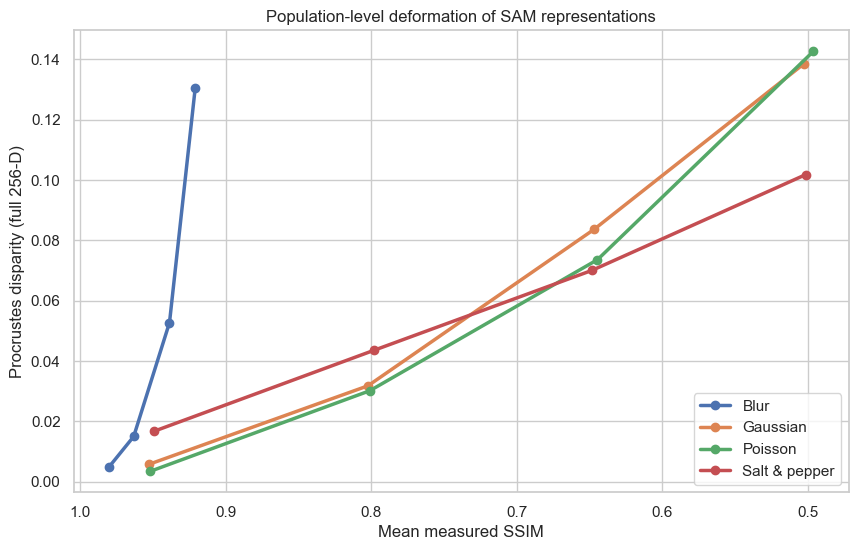

,noise_type,target_ssim,actual_ssim,disparity
3,blur,0.98,0.9801,0.0048
2,blur,0.96,0.9631,0.0149
1,blur,0.94,0.9385,0.0527
0,blur,0.92,0.9208,0.1304
7,gaussian,0.95,0.9525,0.0057
6,gaussian,0.80,0.8023,0.0317
5,gaussian,0.65,0.6469,0.0836
4,gaussian,0.50,0.5030,0.1384
11,poisson,0.95,0.9516,0.0034
10,poisson,0.80,0.8010,0.0301


In [11]:
procrustes_rows = []
for (noise_type, target), group in results.groupby(["noise_type", "target_ssim"]):
    ordered = group.sort_values("image_index").index.to_numpy()
    degraded_population = degraded_scaled[ordered]
    _, _, disparity = procrustes(clean_scaled, degraded_population)
    procrustes_rows.append((noise_type, target, group.actual_ssim.mean(), disparity))
procrustes_df = pd.DataFrame(procrustes_rows, columns=["noise_type", "target_ssim", "actual_ssim", "disparity"])

fig, ax = plt.subplots(figsize=(10, 6))
for noise_type, group in procrustes_df.groupby("noise_type"):
    group = group.sort_values("actual_ssim")
    ax.plot(group.actual_ssim, group.disparity, marker="o", linewidth=2.5, label=DISPLAY_NAME[noise_type])
ax.set(xlabel="Mean measured SSIM", ylabel="Procrustes disparity (full 256-D)", title="Population-level deformation of SAM representations")
ax.invert_xaxis(); ax.legend(); plt.show()
display(procrustes_df.sort_values(["noise_type", "actual_ssim"], ascending=[True, False]).round(4))


## 9. Does each degraded image keep the same clean-image identity?

We treat the clean embeddings as a small reference gallery. For every degraded embedding, cosine similarity identifies its nearest clean reference. `identity_retained=True` means it still retrieves its own clean image. This is a stricter and often more interpretable test than a smooth average similarity curve.


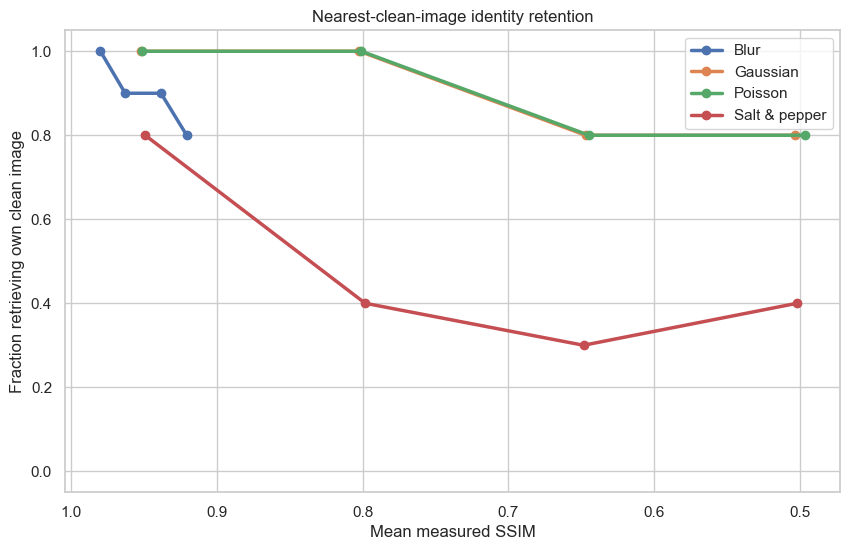

,filename,noise_type,actual_ssim,nearest_clean_filename,cosine_similarity
111,image_01.png,blur,0.9139,image_03.png,0.9417
109,image_09.png,blur,0.9297,image_01.png,0.9881
119,image_09.png,blur,0.9297,image_01.png,0.9881
99,image_09.png,blur,0.9619,image_01.png,0.9924
39,image_09.png,gaussian,0.5021,image_01.png,0.9858
36,image_06.png,gaussian,0.5029,image_07.png,0.8817
26,image_06.png,gaussian,0.6439,image_07.png,0.9383
29,image_09.png,gaussian,0.6498,image_01.png,0.9891
76,image_06.png,poisson,0.5038,image_07.png,0.8927
79,image_09.png,poisson,0.5053,image_07.png,0.9861


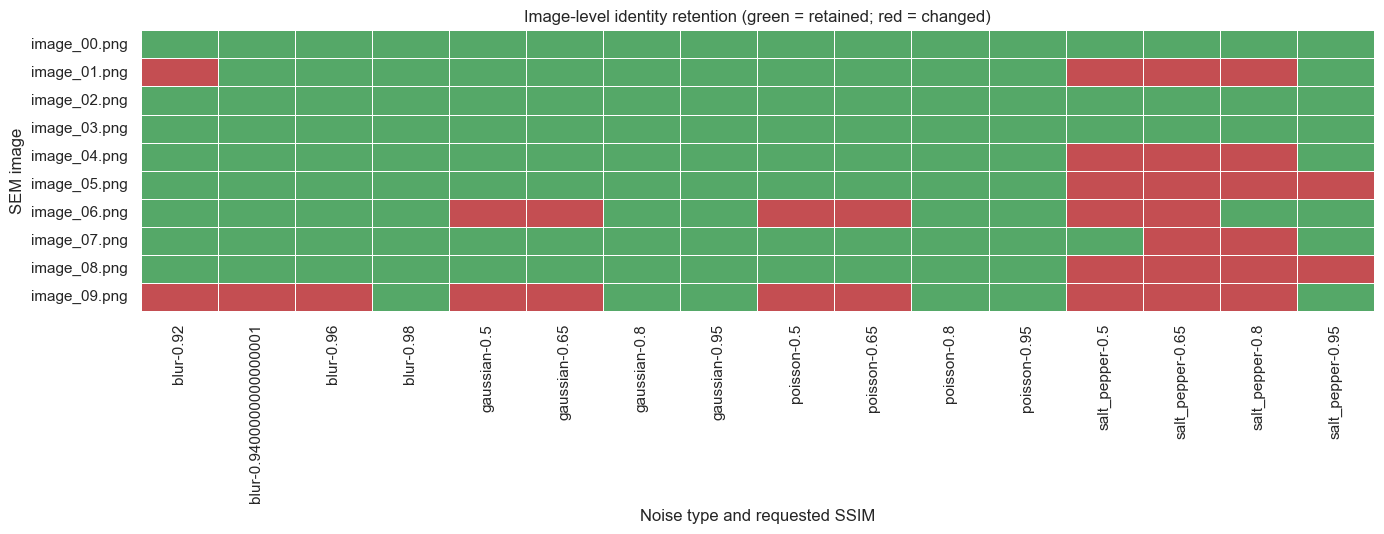

In [12]:
retention = results.groupby(["noise_type", "target_ssim"]).agg(actual_ssim=("actual_ssim", "mean"), retention_rate=("identity_retained", "mean")).reset_index()
fig, ax = plt.subplots(figsize=(10, 6))
for noise_type, group in retention.groupby("noise_type"):
    group = group.sort_values("actual_ssim")
    ax.plot(group.actual_ssim, group.retention_rate, marker="o", linewidth=2.5, label=DISPLAY_NAME[noise_type])
ax.set(xlabel="Mean measured SSIM", ylabel="Fraction retrieving own clean image", ylim=(-0.05, 1.05), title="Nearest-clean-image identity retention")
ax.invert_xaxis(); ax.legend(); plt.show()

identity_table = results.pivot_table(index="filename", columns=["noise_type", "target_ssim"], values="identity_retained", aggfunc="first")
plt.figure(figsize=(14, max(4, 0.55 * len(identity_table))))
sns.heatmap(identity_table.astype(float), cmap=["#C44E52", "#55A868"], vmin=0, vmax=1, cbar=False, linewidths=0.5)
plt.title("Image-level identity retention (green = retained; red = changed)")
plt.xlabel("Noise type and requested SSIM"); plt.ylabel("SEM image"); plt.tight_layout()

changed = results[~results.identity_retained][["filename", "noise_type", "actual_ssim", "nearest_clean_filename", "cosine_similarity"]]
display(changed.sort_values(["noise_type", "actual_ssim"]).round(4) if len(changed) else pd.DataFrame({"result": ["No identity changes observed at these levels."]}))


## 10. An Oxford Loss Landscapes–style view of SAM prediction stability

The preceding sections perturb **images** and measure their representations. We now ask a different question: if SAM's learned mask-decoder parameters move slightly, do its predictions remain similar? This follows the random-plane, filter-normalized idea used by [Oxford Loss Landscapes](https://github.com/TRustworthy-AI-Tools-for-Science/oxford-loss-landscapes), implemented locally here to preserve this notebook's working NumPy environment.

### What counts as a prediction task here?

These SEM images have no ground-truth masks. We therefore give every clean image the same reproducible **positive point prompt at its centre** and treat unperturbed SAM's mask as a reference prediction. The plotted quantity is a *prediction-consistency pseudo-loss*, not segmentation error:

$$L_{\mathrm{consistency}} = 1 - \frac{2\langle p_0,p_{\alpha,\beta}\rangle + \epsilon}{\lVert p_0\rVert_2^2 + \lVert p_{\alpha,\beta}\rVert_2^2 + \epsilon},$$

where $p_0$ is the baseline mask-probability map and $p_{\alpha,\beta}$ is the prediction after moving in two parameter-space directions. This squared soft-Dice form is exactly zero when the two probability maps match. We also report thresholded-mask IoU and absolute predicted-area change, which are often easier to explain. Metrics use SAM's native 256×256 decoder grid; image displays resize binary masks with nearest-neighbour interpolation.

### Why perturb only the mask decoder?

The image encoder contains most of ViT-B's parameters and is expensive to rerun at every grid point. Holding its clean spatial embeddings fixed isolates the local stability of the **prompt-conditioned mask decoder** and makes a 7×7 surface practical on this laptop. It does **not** establish the stability of the complete SAM model, prediction accuracy, or scientific validity.


In [ ]:
# A 3×3 grid keeps smoke tests quick; the teaching run uses a symmetric 7×7 grid.
LANDSCAPE_STEPS = 3 if SMOKE_TEST else 7
LANDSCAPE_HALF_WIDTH = 0.01  # ±1% along each filter-normalized direction
LANDSCAPE_DIRECTION_SEED = SEED + 420
landscape_axis = np.linspace(-LANDSCAPE_HALF_WIDTH, LANDSCAPE_HALF_WIDTH, LANDSCAPE_STEPS)

@torch.inference_mode()
def decode_fixed_record(record):
    low_res_logits, quality = sam.mask_decoder(
        image_embeddings=record["image_embedding"],
        image_pe=sam.prompt_encoder.get_dense_pe(),
        sparse_prompt_embeddings=record["sparse_prompt"],
        dense_prompt_embeddings=record["dense_prompt"],
        multimask_output=False,
    )
    return low_res_logits[:, :1], quality[:, :1]

@torch.inference_mode()
def prepare_fixed_prompt_records(images):
    records = []
    for image in tqdm(images, desc="Clean SAM spatial embeddings and prompts"):
        predictor.set_image(to_sam_rgb(image))
        height, width = image.shape
        point_xy = np.array([[width / 2, height / 2]], dtype=np.float32)
        transformed = predictor.transform.apply_coords(point_xy, predictor.original_size)
        point_coords = torch.as_tensor(transformed, dtype=torch.float32, device=device)[None, :, :]
        point_labels = torch.ones((1, 1), dtype=torch.int64, device=device)
        sparse, dense = sam.prompt_encoder(points=(point_coords, point_labels), boxes=None, masks=None)
        record = {
            "image_embedding": predictor.get_image_embedding().detach().clone(),
            "sparse_prompt": sparse.detach().clone(),
            "dense_prompt": dense.detach().clone(),
            "point_xy": point_xy[0],
        }
        baseline_logits, baseline_quality = decode_fixed_record(record)
        record["baseline_logits"] = baseline_logits.detach().clone()
        record["baseline_probability"] = torch.sigmoid(baseline_logits).detach().clone()
        record["baseline_mask"] = (baseline_logits > sam.mask_threshold).detach().clone()
        record["baseline_quality"] = float(baseline_quality.item())
        records.append(record)
    return records

fixed_prompt_records = prepare_fixed_prompt_records(clean_images)
print(f"Prepared {len(fixed_prompt_records)} fixed-prompt reference predictions.")

# Show what the pseudo-targets actually are before trusting any landscape summary.
shown = min(4, len(clean_images))
fig, axes = plt.subplots(1, shown, figsize=(4 * shown, 4))
for image_index, ax in enumerate(np.atleast_1d(axes)):
    baseline_small = fixed_prompt_records[image_index]["baseline_mask"][0, 0].cpu().numpy().astype(np.uint8)
    baseline_mask = np.asarray(Image.fromarray(baseline_small).resize(clean_images[image_index].shape[::-1], Image.Resampling.NEAREST), dtype=bool)
    ax.imshow(clean_images[image_index], cmap="gray", vmin=0, vmax=1)
    ax.imshow(np.ma.masked_where(~baseline_mask, baseline_mask), cmap="autumn", alpha=0.40, vmin=0, vmax=1)
    px, py = fixed_prompt_records[image_index]["point_xy"]
    ax.scatter(px, py, marker="+", s=130, linewidths=2.5, color="cyan")
    ax.set_title(f"{filenames[image_index]}\nbaseline mask; centre prompt")
    ax.axis("off")
fig.suptitle("Reference predictions are SAM pseudo-targets—not ground truth", fontsize=15)
plt.tight_layout()


### Construct the local parameter plane

Two seeded Gaussian directions are made approximately orthogonal, then normalized filter by filter to the corresponding baseline parameter norms. Bias vectors are normalized as whole layers. After one final global rescaling, a coefficient of `0.01` means a direction whose total L2 length is 1% of the decoder's baseline parameter norm. At a corner, both directions act simultaneously.

Filter normalization reduces misleading scale effects across layers, but this is still one randomly oriented local slice. A second seed can reveal a different surface.


In [ ]:
decoder_parameters = list(sam.mask_decoder.parameters())
baseline_decoder_parameters = [parameter.detach().clone() for parameter in decoder_parameters]

def vector_dot(left, right):
    return sum(float(torch.sum(a * b).item()) for a, b in zip(left, right))

def vector_norm(vector):
    return float(np.sqrt(max(vector_dot(vector, vector), 0.0)))

def filter_normalize_direction(direction, reference, eps=1e-12):
    normalized = []
    for random_tensor, reference_tensor in zip(direction, reference):
        current = random_tensor.clone()
        if current.ndim <= 1:
            current_norm = current.norm()
            reference_norm = reference_tensor.norm()
            current.mul_(reference_norm / current_norm.clamp_min(eps))
        else:
            current_flat = current.reshape(current.shape[0], -1)
            reference_flat = reference_tensor.reshape(reference_tensor.shape[0], -1)
            scales = reference_flat.norm(dim=1) / current_flat.norm(dim=1).clamp_min(eps)
            current.mul_(scales.reshape((-1,) + (1,) * (current.ndim - 1)))
        normalized.append(current)
    return normalized

def make_filter_normalized_directions(reference, seed):
    generator = torch.Generator(device="cpu").manual_seed(seed)
    direction_one = [torch.randn(p.shape, generator=generator, dtype=p.dtype).to(p.device) for p in reference]
    direction_two = [torch.randn(p.shape, generator=generator, dtype=p.dtype).to(p.device) for p in reference]

    # Gram–Schmidt before filter normalization, matching the Oxford-style construction.
    projection = vector_dot(direction_two, direction_one) / max(vector_dot(direction_one, direction_one), 1e-30)
    direction_two = [b - projection * a for a, b in zip(direction_one, direction_two)]
    direction_one = filter_normalize_direction(direction_one, reference)
    direction_two = filter_normalize_direction(direction_two, reference)

    # Give both complete directions exactly the decoder's baseline L2 norm.
    reference_norm = vector_norm(reference)
    direction_one = [d * (reference_norm / vector_norm(direction_one)) for d in direction_one]
    direction_two = [d * (reference_norm / vector_norm(direction_two)) for d in direction_two]
    return direction_one, direction_two

direction_one, direction_two = make_filter_normalized_directions(baseline_decoder_parameters, LANDSCAPE_DIRECTION_SEED)
direction_cosine = vector_dot(direction_one, direction_two) / (vector_norm(direction_one) * vector_norm(direction_two))
print(f"Decoder parameters: {sum(p.numel() for p in decoder_parameters):,}")
print(f"Cosine between normalized directions: {direction_cosine:.6f}")

@torch.no_grad()
def set_decoder_position(alpha, beta):
    for parameter, baseline, first, second in zip(decoder_parameters, baseline_decoder_parameters, direction_one, direction_two):
        parameter.copy_(baseline + alpha * first + beta * second)

@torch.no_grad()
def restore_decoder():
    for parameter, baseline in zip(decoder_parameters, baseline_decoder_parameters):
        parameter.copy_(baseline)

@torch.inference_mode()
def prediction_consistency_metrics(record):
    candidate_logits, _ = decode_fixed_record(record)
    candidate_probability = torch.sigmoid(candidate_logits)
    reference_probability = record["baseline_probability"]
    numerator = 2 * torch.sum(candidate_probability * reference_probability) + 1e-7
    denominator = torch.sum(candidate_probability.square()) + torch.sum(reference_probability.square()) + 1e-7
    consistency_loss = torch.clamp(1 - numerator / denominator, min=0)

    candidate_mask = candidate_logits > sam.mask_threshold
    reference_mask = record["baseline_mask"]
    intersection = torch.logical_and(candidate_mask, reference_mask).sum()
    union = torch.logical_or(candidate_mask, reference_mask).sum()
    mask_iou = torch.where(union > 0, intersection.float() / union.float(), torch.ones_like(union, dtype=torch.float32))
    area_change = torch.abs(candidate_mask.float().mean() - reference_mask.float().mean())
    return float(consistency_loss.item()), float(mask_iou.item()), float(area_change.item())


In [ ]:
landscape_config = {
    "version": 1,
    "model": "sam_vit_b_01ec64",
    "files": filenames.tolist(),
    "prompt": "one positive point at image centre",
    "decoder_only": True,
    "steps": LANDSCAPE_STEPS,
    "half_width": LANDSCAPE_HALF_WIDTH,
    "direction_seed": LANDSCAPE_DIRECTION_SEED,
}
landscape_config_json = json.dumps(landscape_config, sort_keys=True)
landscape_tag = hashlib.sha256(landscape_config_json.encode()).hexdigest()[:12]
LANDSCAPE_CACHE_PATH = ARTIFACT_DIR / f"sam_vit_b_decoder_landscape_{landscape_tag}.npz"

if LANDSCAPE_CACHE_PATH.exists() and not FORCE_RECOMPUTE:
    landscape_cache = np.load(LANDSCAPE_CACHE_PATH, allow_pickle=False)
    assert str(landscape_cache["config_json"]) == landscape_config_json
    per_image_loss = landscape_cache["per_image_loss"]
    per_image_iou = landscape_cache["per_image_iou"]
    per_image_area_change = landscape_cache["per_image_area_change"]
    print("Loaded cached prediction-stability landscape.")
else:
    shape = (LANDSCAPE_STEPS, LANDSCAPE_STEPS, len(clean_images))
    per_image_loss = np.empty(shape, dtype=np.float32)
    per_image_iou = np.empty(shape, dtype=np.float32)
    per_image_area_change = np.empty(shape, dtype=np.float32)
    started = time.perf_counter()
    try:
        for row, beta in enumerate(tqdm(landscape_axis, desc="Decoder prediction-stability plane")):
            for column, alpha in enumerate(landscape_axis):
                set_decoder_position(float(alpha), float(beta))
                for image_index, record in enumerate(fixed_prompt_records):
                    loss, iou, area_change = prediction_consistency_metrics(record)
                    per_image_loss[row, column, image_index] = loss
                    per_image_iou[row, column, image_index] = iou
                    per_image_area_change[row, column, image_index] = area_change
    finally:
        restore_decoder()
    np.savez_compressed(
        LANDSCAPE_CACHE_PATH, config_json=landscape_config_json,
        per_image_loss=per_image_loss, per_image_iou=per_image_iou,
        per_image_area_change=per_image_area_change,
    )
    print(f"Computed landscape in {time.perf_counter() - started:.1f} seconds and saved its cache.")

restoration_error = max(float((parameter - baseline).abs().max().item()) for parameter, baseline in zip(decoder_parameters, baseline_decoder_parameters))
assert restoration_error == 0.0, f"Decoder restoration failed: max error {restoration_error}"
center = LANDSCAPE_STEPS // 2
assert np.max(per_image_loss[center, center]) < 1e-6
assert np.min(per_image_iou[center, center]) > 1 - 1e-6
print(f"Exact decoder restoration verified; centre loss ≤ {per_image_loss[center, center].max():.2e}.")


In [ ]:
x_percent, y_percent = np.meshgrid(100 * landscape_axis, 100 * landscape_axis)
mean_loss = per_image_loss.mean(axis=2)
mean_iou = per_image_iou.mean(axis=2)
mean_area_change = per_image_area_change.mean(axis=2)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
surfaces = [
    (mean_loss, "Mean consistency loss ↓", "magma"),
    (mean_iou, "Mean mask IoU ↑", "viridis"),
    (100 * mean_area_change, "Mean absolute area change (percentage points) ↓", "cividis"),
]
for ax, (surface, title, cmap) in zip(axes, surfaces):
    contour = ax.contourf(x_percent, y_percent, surface, levels=15, cmap=cmap)
    ax.scatter(0, 0, marker="*", s=180, color="cyan", edgecolor="black", label="unperturbed")
    ax.set(title=title, xlabel="Direction 1 coefficient (%)", ylabel="Direction 2 coefficient (%)")
    fig.colorbar(contour, ax=ax, shrink=0.85)
axes[0].legend(loc="upper right")
fig.suptitle("Aggregate local prediction stability of SAM's mask decoder", fontsize=15)
plt.tight_layout()

# Small multiples expose images whose instability is hidden by the mean surface.
columns = 5
rows = int(np.ceil(len(clean_images) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(16, 3.1 * rows), sharex=True, sharey=True, squeeze=False)
common_max = max(float(per_image_loss.max()), 1e-8)
levels = np.linspace(0, common_max, 13)
for image_index, ax in enumerate(axes.ravel()):
    if image_index >= len(clean_images):
        ax.axis("off"); continue
    contour = ax.contourf(x_percent, y_percent, per_image_loss[:, :, image_index], levels=levels, cmap="magma", vmin=0, vmax=common_max)
    ax.scatter(0, 0, marker="*", s=75, color="cyan", edgecolor="black")
    ax.set_title(f"{filenames[image_index]}\nmax loss={per_image_loss[:, :, image_index].max():.4f}")
    ax.set_xlabel("Direction 1 (%)"); ax.set_ylabel("Direction 2 (%)")
fig.colorbar(contour, ax=axes.ravel().tolist(), shrink=0.8, label="Prediction-consistency loss")
fig.suptitle("Image-level landscapes: the shared colour scale makes failures comparable", fontsize=15, y=1.02)
plt.show()

landscape_summary = pd.DataFrame({
    "filename": filenames,
    "maximum_consistency_loss": per_image_loss.max(axis=(0, 1)),
    "minimum_mask_iou": per_image_iou.min(axis=(0, 1)),
    "maximum_area_change_pp": 100 * per_image_area_change.max(axis=(0, 1)),
}).sort_values("minimum_mask_iou")
display(landscape_summary.round(4))


In [ ]:
# Reconstruct the single lowest-IoU prediction so students can see the failure behind the statistic.
worst_row, worst_column, worst_image_index = np.unravel_index(np.argmin(per_image_iou), per_image_iou.shape)
worst_alpha = float(landscape_axis[worst_column])
worst_beta = float(landscape_axis[worst_row])
try:
    set_decoder_position(worst_alpha, worst_beta)
    with torch.inference_mode():
        worst_logits, _ = decode_fixed_record(fixed_prompt_records[worst_image_index])
        worst_small = (worst_logits > sam.mask_threshold)[0, 0].cpu().numpy().astype(np.uint8)
finally:
    restore_decoder()

baseline_small = fixed_prompt_records[worst_image_index]["baseline_mask"][0, 0].cpu().numpy().astype(np.uint8)
output_size = clean_images[worst_image_index].shape[::-1]
baseline_mask = np.asarray(Image.fromarray(baseline_small).resize(output_size, Image.Resampling.NEAREST), dtype=bool)
perturbed_mask = np.asarray(Image.fromarray(worst_small).resize(output_size, Image.Resampling.NEAREST), dtype=bool)
changed_pixels = np.logical_xor(baseline_mask, perturbed_mask)

fig, axes = plt.subplots(1, 4, figsize=(17, 4))
axes[0].imshow(clean_images[worst_image_index], cmap="gray", vmin=0, vmax=1)
px, py = fixed_prompt_records[worst_image_index]["point_xy"]
axes[0].scatter(px, py, marker="+", s=140, linewidths=2.5, color="cyan")
axes[0].set_title("Clean SEM + fixed prompt")
for ax, mask, title in [
    (axes[1], baseline_mask, "Unperturbed reference mask"),
    (axes[2], perturbed_mask, f"Perturbed mask\nIoU={per_image_iou[worst_row, worst_column, worst_image_index]:.3f}"),
    (axes[3], changed_pixels, f"Pixels changing class\n{100 * changed_pixels.mean():.2f}% of image"),
]:
    ax.imshow(clean_images[worst_image_index], cmap="gray", vmin=0, vmax=1)
    ax.imshow(np.ma.masked_where(~mask, mask), cmap="autumn", alpha=0.48, vmin=0, vmax=1)
    ax.set_title(title)
for ax in axes: ax.axis("off")
fig.suptitle(
    f"Largest individual thresholded-mask change: {filenames[worst_image_index]} | "
    f"directions=({100 * worst_alpha:+.1f}%, {100 * worst_beta:+.1f}%)", fontsize=15
)
plt.tight_layout()


### Reading the stability landscape

- A broad dark basin near the star indicates locally consistent probabilities in this particular plane; a rapid colour change indicates sensitivity.
- Mask IoU can stay exactly 1 while the soft consistency loss rises, because probabilities can move without crossing the binary threshold. Conversely, a few boundary pixels crossing the threshold can noticeably reduce IoU.
- Area change can be small even when different pixels enter and leave the mask. Read it alongside IoU, not alone.
- The mean surface and the image-level panels answer different Trust in AI questions. A stable population average does not protect a vulnerable microstructure.
- The cyan star is a reference prediction, **not a proven optimum**. With no human masks, low consistency loss means agreement with SAM itself—not correctness.
- This is one seeded two-dimensional slice through a high-dimensional decoder. Repeat with other direction seeds and scientifically meaningful prompts before making a strong robustness claim.


## 11. Interpretation guardrails

Before drawing a Trust in AI conclusion, keep these limits visible:

- This is **ViT-B**, one random realization per image/noise/level, and a small ten-image population. Repeated noise realizations would support uncertainty estimates.
- SAM was trained on natural-image segmentation data, not specifically on SEM microstructures. Stability does not guarantee scientific validity.
- Global-average pooling removes spatial information. A local defect could disappear while the pooled vector remains stable.
- Equal SSIM does not mean equal physical severity or equal preservation of microstructural evidence.
- Cosine similarity and Euclidean distance answer different geometric questions.
- Procrustes ignores translation, rotation/reflection, and overall scale; neighbour retrieval can fail even when population disparity is modest.
- PCA is fitted only on clean data and shows two axes. It is a map for seeing trajectories, not the basis of the full-space robustness claims.
- The decoder landscape uses pseudo-target masks, one fixed centre prompt, one random parameter plane, and frozen clean image embeddings. It measures local decoder consistency—not complete-model robustness or segmentation accuracy.


## Synthesis questions

1. **How much image degradation can SAM tolerate before its representation meaningfully changes?** State what you count as “meaningful” before reading the plots.
2. Does the apparent tolerance threshold change when you use cosine similarity, Euclidean distance, nearest-neighbour identity, or Procrustes disparity? Why?
3. Which noise process creates the largest representation change at comparable SSIM? What does that reveal about SSIM as a matching variable?
4. Find an image whose trajectory is much worse than the population average. What morphological feature might explain its vulnerability?
5. Can the population geometry remain fairly stable while one image changes its nearest clean neighbour? What risk would that create in a retrieval or clustering application?
6. Can a long two-dimensional PCA trajectory coexist with a high full-space cosine similarity? Explain why PCA visualization and full-space measurement need not agree.
7. Does the decoder's aggregate landscape hide an unstable individual image? Compare the mean surface, image-level landscapes, and worst-case mask.
8. Why can mask IoU remain unchanged while the soft consistency loss increases? Which measure would matter more in a particular SEM decision?
9. How would real expert-annotated masks change the meaning of this landscape?
10. What additional evidence—repeat corruptions, more microstructures, another SAM backbone, spatial embeddings, prompts, parameter-plane seeds, or expert masks—would you require before claiming that SAM is robust for SEM use?

> **Final prompt:** Does “SAM is robust” have one answer, or does the answer depend on whether we examine individual images, neighbourhood identity, population representation space, or local prediction stability?
